# Compact candidate set and temporal transfer

**Question:** How much predictive and warning information survives substantial reduction, and what should be frozen for a genuinely future cohort?

Candidates include the full feasible space, prior 62 fields, correlation representatives, profile/departure blocks, background context, sparse selected values and cluster representatives at four selection-frequency thresholds. Identical feature sets are deduplicated. Every comparison uses the same L2 model and training-only preprocessing.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/feature_consolidation.yaml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import json
import pandas as pd
from IPython.display import display,Markdown,Image
from src.injury_analysis.consolidation_common import OUT,CACHE,read_table
assert (OUT/'candidate_freeze.json').exists(), 'First run: .venv/bin/python -m src.injury_analysis.consolidation_workflow'
def plot(name):display(Image(filename=str(OUT/'figures'/f'{name}.png')))
display(read_table('cohort_counts'))
display(read_table('event_support'))

,partition,rows,positive_rows,pitchers,prevalence
0,test,27665,708,789,0.025592
1,train,81145,1441,1290,0.017758
2,validation,26796,600,783,0.022391


,partition,rows,positive_rows,represented_events,initial_explicit_ucl_events,later_supplemental_ucl_confirmation,first_appearance,last_appearance
0,test,27665,708,110,5,24,2024-03-20,2025-09-24
1,train,81145,1441,223,15,46,2015-04-14,2021-09-24
2,validation,26796,600,89,3,17,2022-04-07,2023-09-29


## Predeclared validation-only selection rule

Retain candidates within one paired-bootstrap AP standard error of the highest validation AP. Among those, require at most two fewer events warned than the best 5% alert-budget count. Choose the smallest input set that passes, breaking ties by AP. This pragmatic tolerance is not a statistical equivalence claim; repeated validation use remains a development limitation.

The connecting line below joins **nonnested** candidate sets to aid reading; it is not a monotonic feature-elimination path. Missingness indicators are additional fitted design columns.

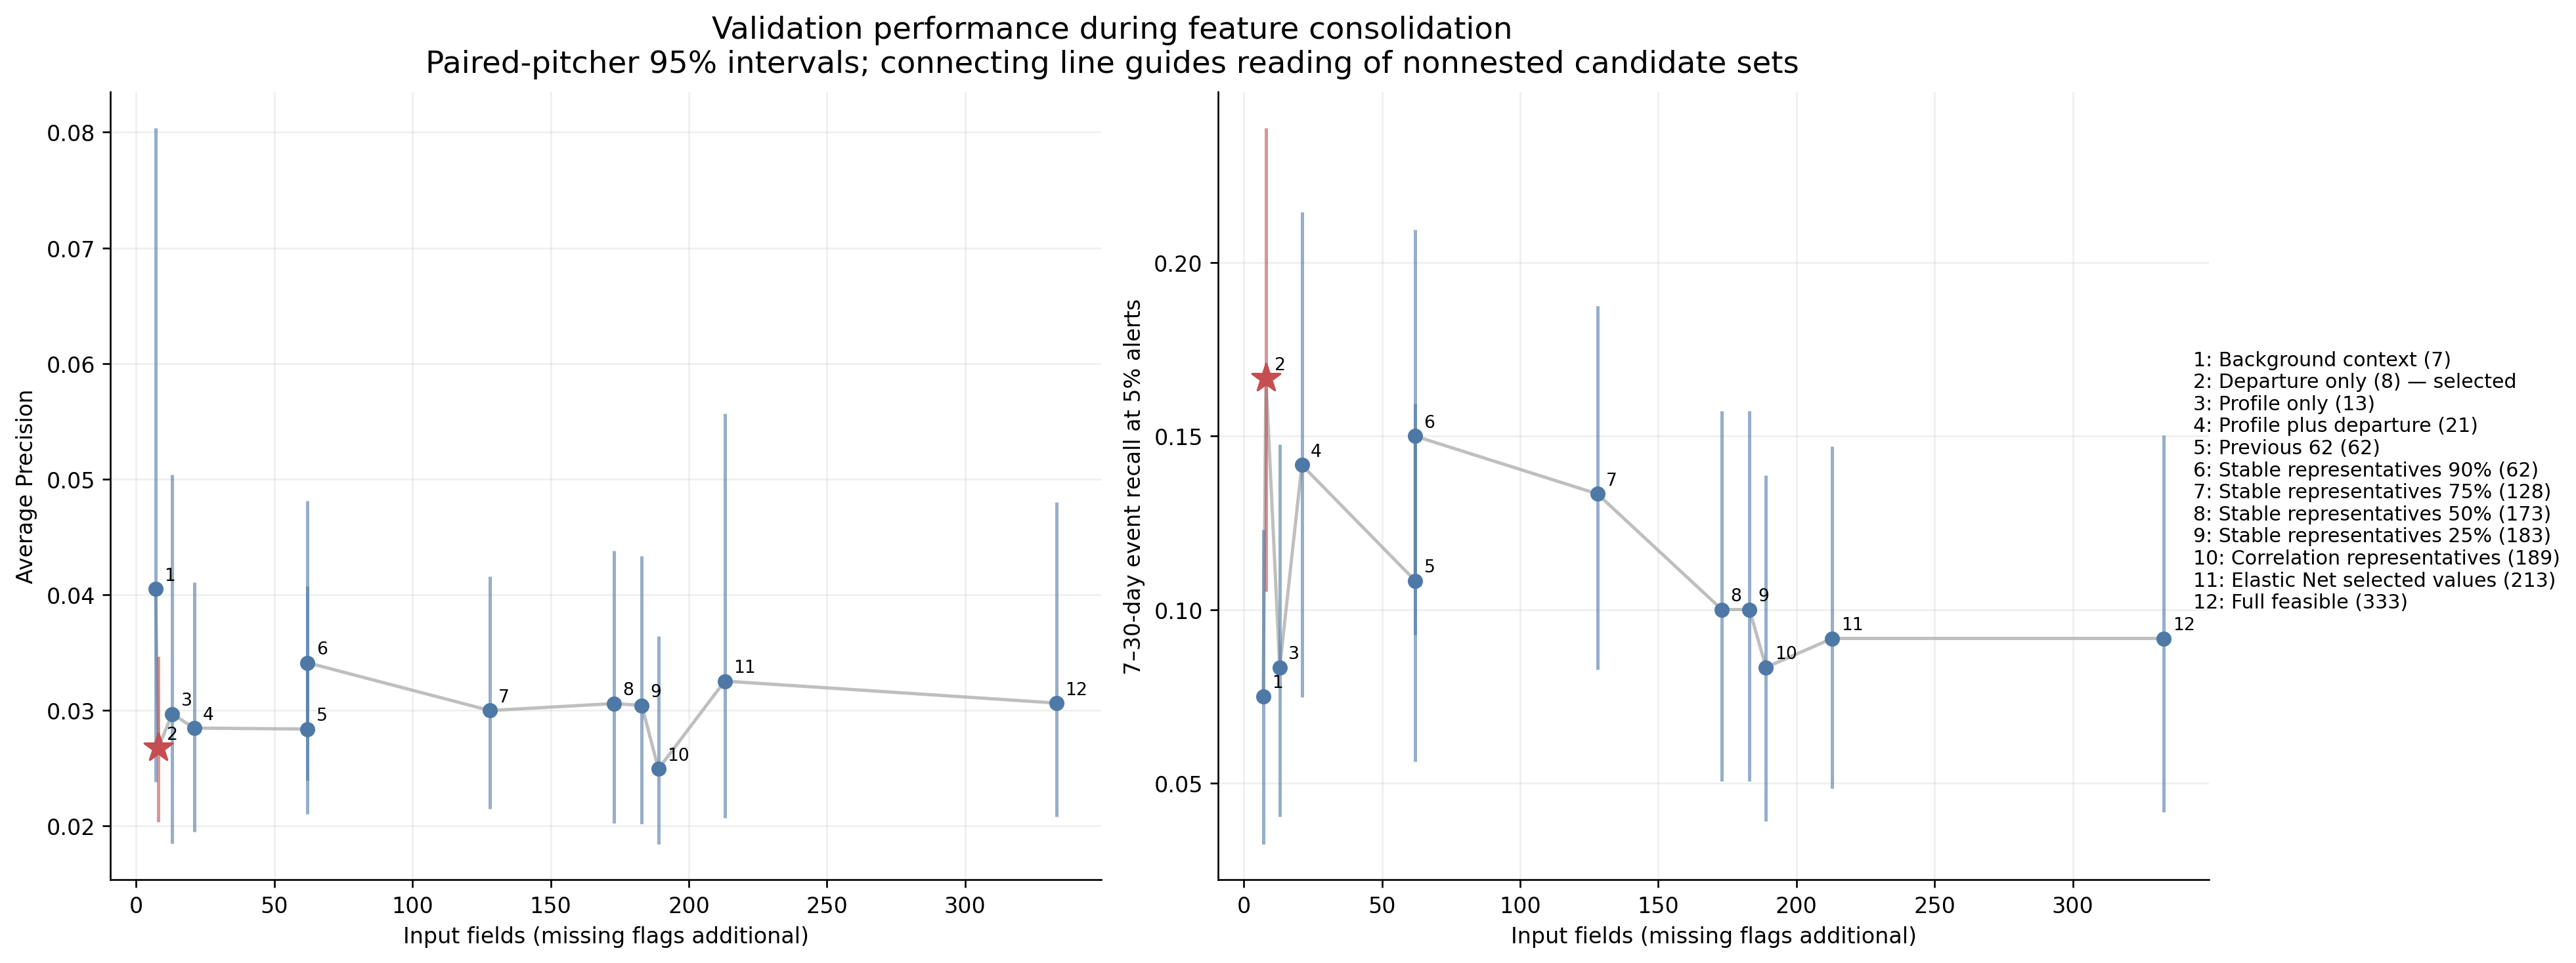

,variant,partition,features,design_columns,event_low,event_high,rows,positive_rows,represented_events,prevalence,...,non_actionable_alerts_per_pitcher_season,precision,recall,ap_low,ap_high,ap_loss_from_best,paired_ap_se,ap_competitive,warning_competitive,selected
0,Full feasible,validation,333,569,0.041652,0.150245,26796,600,89,0.022391,...,1.079339,0.037341,0.083333,0.020762,0.048003,0.009860,0.014967,True,False,False
1,Previous 62,validation,62,107,0.056199,0.159397,26796,600,89,0.022391,...,1.088430,0.032114,0.071667,0.021043,0.040727,0.012109,0.013768,True,False,False
2,Correlation representatives,validation,189,311,0.039050,0.138694,26796,600,89,0.022391,...,1.091736,0.026886,0.060000,0.018416,0.036432,0.015564,0.014363,False,False,False
3,Profile only,validation,13,22,0.040309,0.147541,26796,600,89,0.022391,...,1.063636,0.053025,0.118333,0.018459,0.050392,0.010799,0.013481,True,False,False
4,Departure only,validation,8,16,0.105244,0.238922,26796,600,89,0.022391,...,1.084298,0.032860,0.073333,0.020339,0.034641,0.013741,0.014149,True,True,True
5,Profile plus departure,validation,21,38,0.074654,0.214596,26796,600,89,0.022391,...,1.076033,0.041822,0.093333,0.019500,0.041081,0.012027,0.012950,True,False,False
6,Background context,validation,7,8,0.032383,0.123043,26796,600,89,0.022391,...,1.079339,0.039582,0.088333,0.023794,0.080392,0.000000,0.000000,True,False,False
7,Elastic Net selected values,validation,213,374,0.048387,0.147071,26796,600,89,0.022391,...,1.080992,0.035848,0.080000,0.020694,0.055648,0.007961,0.015505,True,False,False
8,Stable representatives 90%,validation,62,104,0.092809,0.209485,26796,600,89,0.022391,...,1.076033,0.046303,0.103333,0.023889,0.048091,0.006372,0.015584,True,True,False
9,Stable representatives 75%,validation,128,223,0.082645,0.187500,26796,600,89,0.022391,...,1.078512,0.042569,0.095000,0.021489,0.041583,0.010509,0.015031,True,False,False


,feature,comparison,alternative,model,ap_loss,event_recall_loss,low,high
0,velo_z,drop,NaN,drop__velo_z,0.003510,-0.008333,0.000182,0.008096
1,release_x_z,drop,NaN,drop__release_x_z,-0.000208,0.008333,-0.001196,0.000819
2,release_z_z,drop,NaN,drop__release_z_z,-0.000010,0.000000,-0.000078,0.000083
3,release_x_sd_z,drop,NaN,drop__release_x_sd_z,0.000124,0.000000,-0.000034,0.000327
4,release_z_sd_z,drop,NaN,drop__release_z_sd_z,0.000098,0.016667,-0.000524,0.000655
5,extension_z,drop,NaN,drop__extension_z,0.000829,0.025000,-0.000541,0.002716
6,spin_z,drop,NaN,drop__spin_z,-0.000194,0.000000,-0.000837,0.000171
7,zone_pct_z,drop,NaN,drop__zone_pct_z,0.000052,-0.008333,-0.000116,0.000281


In [2]:
plot('05_reduction_performance')
display(read_table('candidate_reduction_curve'))
display(read_table('conditional_feature_checks'))

## Measurement support versus substantive predictors

Compare explicit historical support and automatic missingness indicators separately. All alternatives use identical rows. This analysis examines whether availability, role or experience can substitute for measured information; a gain is not evidence about injury physiology. These sensitivity models do not trigger another round of test-driven feature selection.

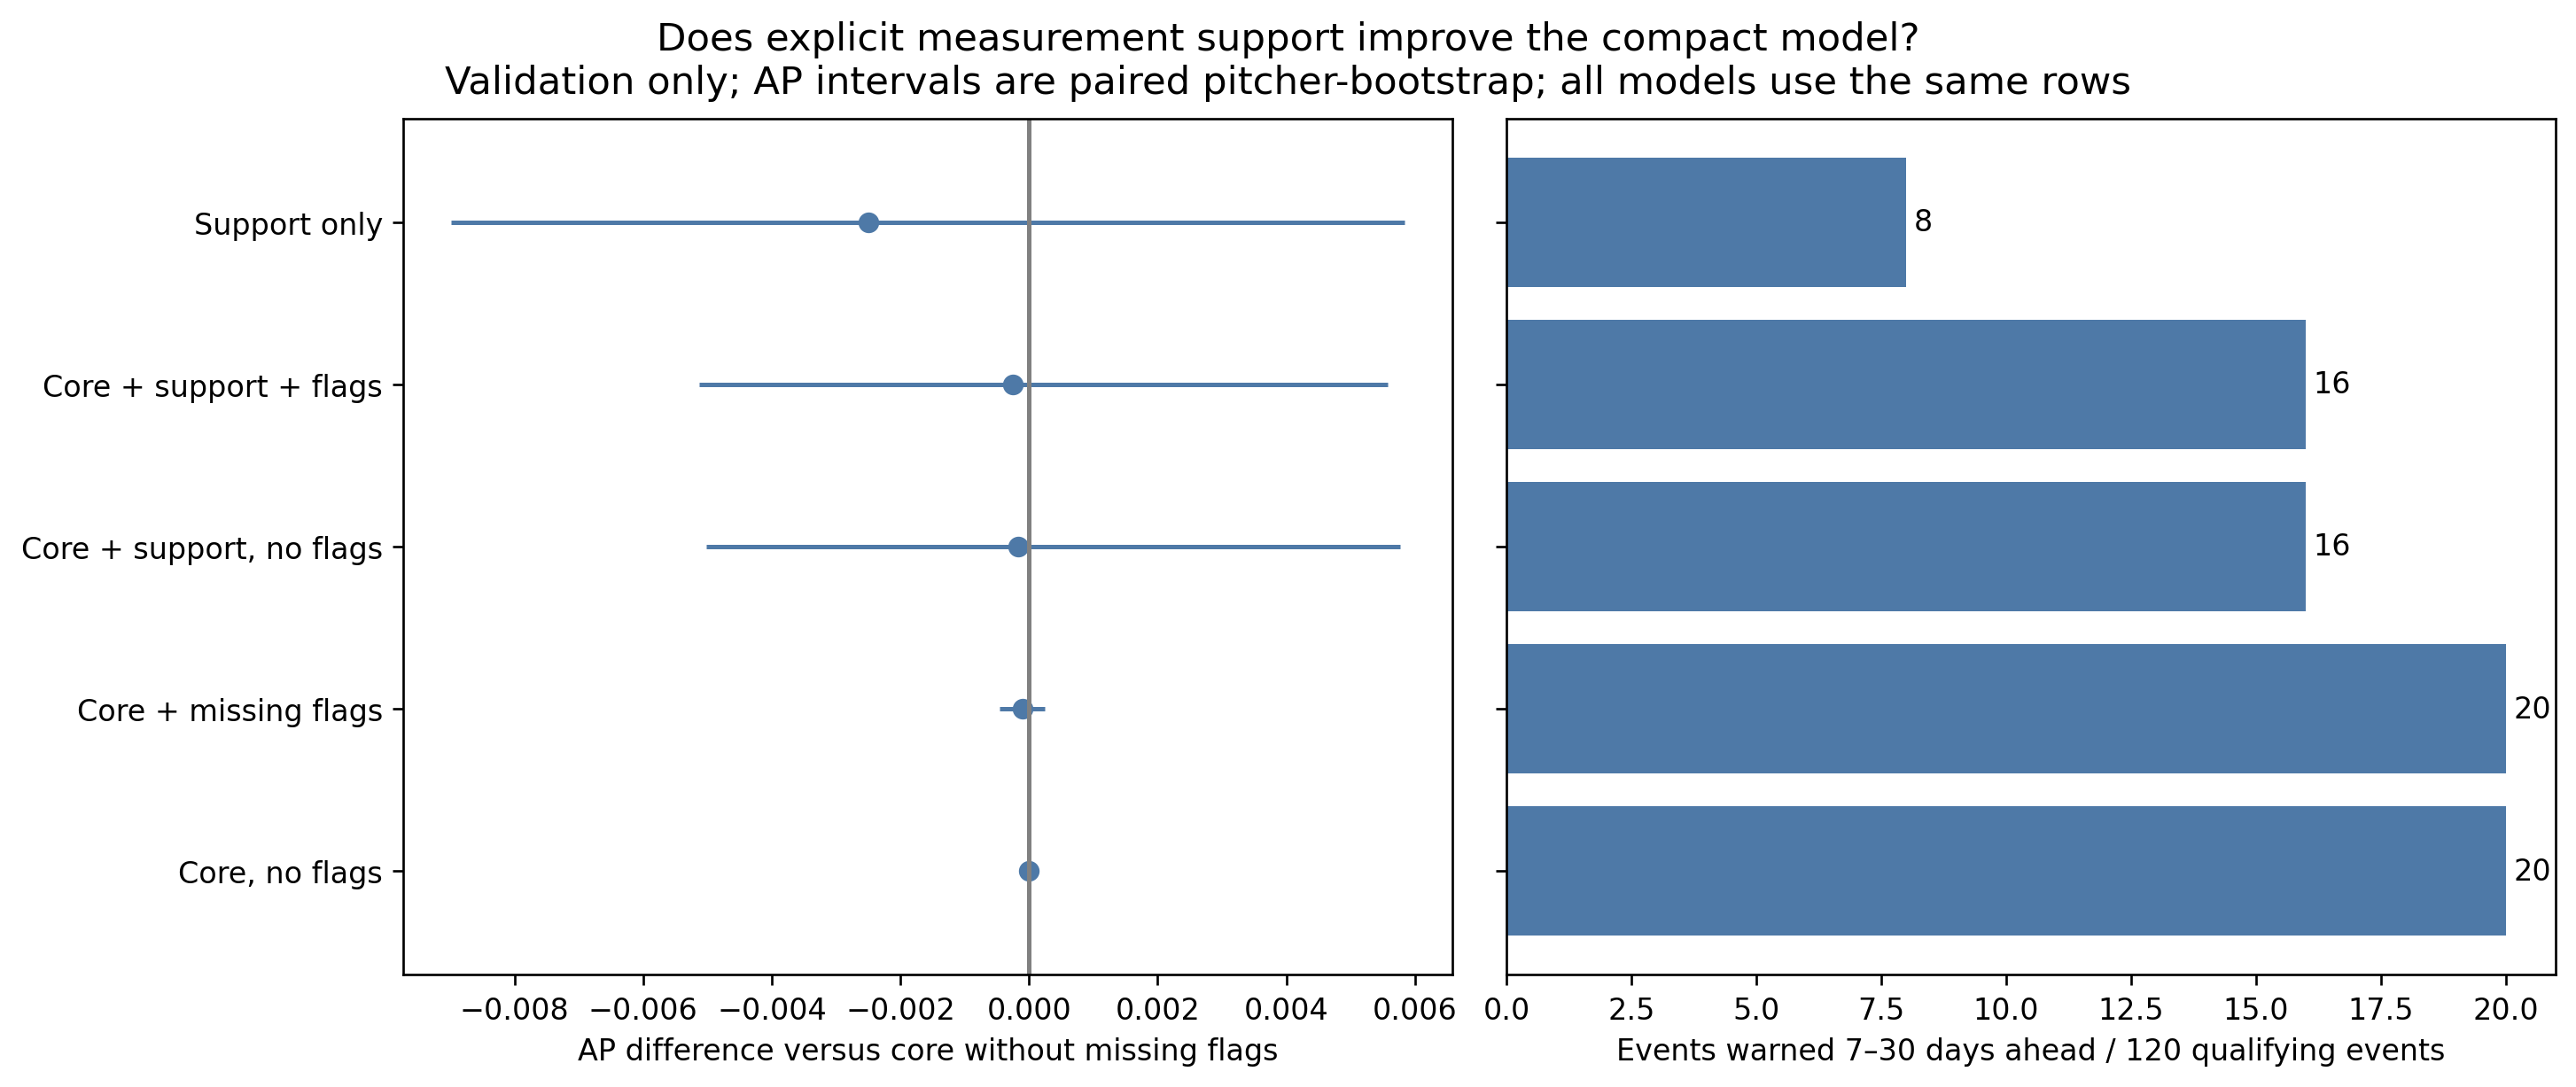

,variant,features,design_columns,rows,positive_rows,represented_events,prevalence,average_precision,roc_auc,pr_lift,...,alerted_events,injury_event_recall,median_warning_lead_days,false_alerts_per_pitcher_season,non_actionable_alerts_per_pitcher_season,precision,recall,ap_difference_from_no_flags,ap_difference_low,ap_difference_high
0,"Core, no flags",8,8,26796,600,89,0.022391,0.026837,0.546535,1.198553,...,20,0.166667,17.5,1.070248,1.084298,0.032860,0.073333,0.000000,0.000000,0.000000
1,Core + missing flags,8,16,26796,600,89,0.022391,0.026734,0.546206,1.193944,...,20,0.166667,17.5,1.070248,1.084298,0.032860,0.073333,-0.000103,-0.000464,0.000248
2,"Core + support, no flags",28,28,26796,600,89,0.022391,0.026663,0.558891,1.190754,...,16,0.133333,20.5,1.068595,1.079339,0.034354,0.076667,-0.000175,-0.005021,0.005763
3,Core + support + flags,28,36,26796,600,89,0.022391,0.026583,0.558872,1.187176,...,16,0.133333,20.5,1.069421,1.080165,0.033607,0.075000,-0.000255,-0.005125,0.005570
4,Support only,20,20,26796,600,89,0.022391,0.024340,0.529593,1.087038,...,8,0.066667,23.5,1.080165,1.084298,0.023898,0.053333,-0.002497,-0.008984,0.005843


,variant,season,is_starter,rows,positive_rows,mean_prediction,prevalence,mean_missing_fraction
0,"Core, no flags",2022,False,10239,219,0.017537,0.021389,0.002075
1,"Core, no flags",2022,True,3041,42,0.017948,0.013811,0.000206
2,"Core, no flags",2023,False,10366,268,0.018093,0.025854,0.002460
3,"Core, no flags",2023,True,3150,71,0.018812,0.022540,0.000278
4,Core + missing flags,2022,False,10239,219,0.017570,0.021389,0.002075
5,Core + missing flags,2022,True,3041,42,0.017961,0.013811,0.000206
6,Core + missing flags,2023,False,10366,268,0.018128,0.025854,0.002460
7,Core + missing flags,2023,True,3150,71,0.018842,0.022540,0.000278
8,"Core + support, no flags",2022,False,10239,219,0.014739,0.021389,0.002075
9,"Core + support, no flags",2022,True,3041,42,0.009575,0.013811,0.000206


In [3]:
plot('06_coverage_sensitivity')
display(read_table('coverage_comparison'))
display(read_table('coverage_role_season_audit'))

## Frozen candidate and already examined 2024–2025 transfer

The exact feature list, preprocessing, fitted model hash and decision-table hashes were frozen **before this stage** generated test scores. The period had been examined in earlier work, so these results are not independent confirmation. No feature or threshold is selected from test results.

Retrospective top-5% ranking controls the within-period alert count but requires the period's score distribution. The separate validation-fixed threshold table shows actual test alert-rate drift. Median warning lead time is among detected events; it does not describe every injury. False alerts within 30 days and non-actionable alerts under the narrower 7–30-day warning definition are reported separately.

In [4]:
display(read_table('frozen_performance'))
display(read_table('frozen_paired_differences'))
display(read_table('validation_fixed_thresholds'))
display(read_table('calibration_bins'))
display(read_table('retained_features')[['feature','feature_group','representation','signal_interpretation',
 'selection_frequency','conditional_sign_stability','ap_loss','low','high','reason_retained']])
display(read_table('final_feature_map'))

,variant,category,partition,analysis,rows,positive_rows,represented_events,pitchers,prevalence,average_precision,roc_auc,brier_score,mean_prediction,observed_rate,calibration_bias,pr_lift,ap_low,ap_high,brier_low,brier_high
0,Departure only,Elbow / UCL,validation,Frozen consolidation transfer,26796,600,89,783,0.022391,0.026734,0.546206,0.021898,0.017980,0.022391,-0.004412,1.193944,0.020339,0.034641,0.016955,0.026979
1,Full feasible,Elbow / UCL,validation,Frozen consolidation transfer,26796,600,89,783,0.022391,0.030615,0.550430,0.022515,0.020554,0.022391,-0.001838,1.367247,0.020762,0.048003,0.017531,0.027477
2,Previous 62,Elbow / UCL,validation,Frozen consolidation transfer,26796,600,89,783,0.022391,0.028366,0.548670,0.022004,0.021460,0.022391,-0.000931,1.266822,0.021043,0.040727,0.017005,0.027044
3,Profile only,Elbow / UCL,validation,Frozen consolidation transfer,26796,600,89,783,0.022391,0.029676,0.515731,0.021890,0.020729,0.022391,-0.001662,1.325348,0.018459,0.050392,0.016979,0.026916
4,Profile plus departure,Elbow / UCL,validation,Frozen consolidation transfer,26796,600,89,783,0.022391,0.028448,0.545309,0.021886,0.020768,0.022391,-0.001624,1.270496,0.019500,0.041081,0.016965,0.026901
5,Departure only,Elbow / UCL,test,Frozen consolidation transfer,27665,708,110,789,0.025592,0.030977,0.555671,0.024976,0.017828,0.025592,-0.007764,1.210410,0.023932,0.038927,0.019864,0.030239
6,Full feasible,Elbow / UCL,test,Frozen consolidation transfer,27665,708,110,789,0.025592,0.027970,0.513149,0.025757,0.019106,0.025592,-0.006486,1.092926,0.020837,0.036969,0.020680,0.031074
7,Previous 62,Elbow / UCL,test,Frozen consolidation transfer,27665,708,110,789,0.025592,0.042540,0.612032,0.024857,0.020226,0.025592,-0.005366,1.662260,0.031181,0.063004,0.019828,0.030041
8,Profile only,Elbow / UCL,test,Frozen consolidation transfer,27665,708,110,789,0.025592,0.025964,0.516549,0.024994,0.020274,0.025592,-0.005318,1.014538,0.019305,0.033699,0.019939,0.030184
9,Profile plus departure,Elbow / UCL,test,Frozen consolidation transfer,27665,708,110,789,0.025592,0.029009,0.542623,0.024977,0.020122,0.025592,-0.005470,1.133540,0.021278,0.038180,0.019912,0.030184


,category,partition,analysis,variant,reference,ap_difference,ap_low,ap_high,brier_difference,brier_low,...,event_events,event_pitchers,event_gained_events,event_lost_events,event_shared_detected_events,event_common_lead_mean,event_common_lead_low,event_common_lead_high,event_common_lead_events,event_common_lead_pitchers
0,Elbow / UCL,validation,Frozen consolidation transfer,Departure only,Full feasible,-0.003880,-0.019453,0.004708,-0.000617,-0.001099,...,120,111,17,8,3,-12.333333,-22.000000,-4.000000,3,3
1,Elbow / UCL,validation,Frozen consolidation transfer,Departure only,Previous 62,-0.001632,-0.011933,0.003178,-0.000106,-0.000230,...,120,111,17,10,3,-1.333333,-4.000000,0.000000,3,3
2,Elbow / UCL,validation,Frozen consolidation transfer,Departure only,Profile only,-0.002942,-0.023384,0.008209,0.000008,-0.000078,...,120,111,19,9,1,-4.000000,NaN,NaN,1,1
3,Elbow / UCL,validation,Frozen consolidation transfer,Departure only,Profile plus departure,-0.001714,-0.010344,0.004411,0.000012,-0.000066,...,120,111,12,9,8,-0.875000,-1.818182,0.000000,8,7
4,Elbow / UCL,test,Frozen consolidation transfer,Departure only,Full feasible,0.003007,-0.003668,0.009329,-0.000781,-0.001136,...,145,129,13,10,5,0.200000,-5.600000,8.000000,5,5
5,Elbow / UCL,test,Frozen consolidation transfer,Departure only,Previous 62,-0.011564,-0.026874,-0.002839,0.000119,-0.000039,...,145,129,8,16,10,-2.200000,-7.300000,4.220000,10,10
6,Elbow / UCL,test,Frozen consolidation transfer,Departure only,Profile only,0.005013,-0.001074,0.012846,-0.000018,-0.000092,...,145,129,17,4,1,0.000000,NaN,NaN,1,1
7,Elbow / UCL,test,Frozen consolidation transfer,Departure only,Profile plus departure,0.001967,-0.001869,0.006430,-0.000001,-0.000063,...,145,129,4,4,14,0.714286,-1.428571,4.285714,14,14


,variant,validation_95th_percentile,test_alert_rate,test_precision
0,Departure only,0.027281,0.045653,0.032462
1,Full feasible,0.069722,0.048220,0.036732
2,Previous 62,0.049927,0.039147,0.059095
3,Profile only,0.030857,0.035026,0.004128
4,Profile plus departure,0.035678,0.042328,0.027327


,partition,variant,bin,rows,positive_rows,mean_prediction,observed_rate,lower,upper
0,validation,Departure only,0,2680,58,0.011110,0.021642,0.000000,0.012510
1,validation,Departure only,1,2680,41,0.013260,0.015299,0.012510,0.013917
2,validation,Departure only,2,2679,48,0.014495,0.017917,0.013917,0.015038
3,validation,Departure only,3,2680,58,0.015568,0.021642,0.015038,0.016113
4,validation,Departure only,4,2679,51,0.016653,0.019037,0.016113,0.017173
...,...,...,...,...,...,...,...,...,...
95,test,Profile plus departure,5,2836,74,0.020359,0.026093,0.019439,0.021386
96,test,Profile plus departure,6,2551,87,0.022428,0.034104,0.021386,0.023541
97,test,Profile plus departure,7,2582,64,0.024866,0.024787,0.023541,0.026432
98,test,Profile plus departure,8,2522,85,0.028540,0.033703,0.026432,0.031136


,feature,feature_group,representation,signal_interpretation,selection_frequency,conditional_sign_stability,ap_loss,low,high,reason_retained
0,velo_z,Velocity,pitcher-relative z-score,Departure,1.0000,1.000000,0.003510,0.000182,0.008096,Pitcher-relative z-score of avg_fb_velo; repre...
1,release_x_z,Release position and variability,pitcher-relative z-score,Departure,1.0000,1.000000,-0.000208,-0.001196,0.000819,Pitcher-relative z-score of release_x_avg; rep...
2,release_z_z,Release position and variability,pitcher-relative z-score,Departure,1.0000,0.875000,-0.000010,-0.000078,0.000083,Pitcher-relative z-score of release_z_avg; rep...
3,release_x_sd_z,Release position and variability,pitcher-relative z-score,Departure,0.9375,0.533333,0.000124,-0.000034,0.000327,Pitcher-relative z-score of release_x_sd; repr...
4,release_z_sd_z,Release position and variability,pitcher-relative z-score,Departure,0.8750,0.928571,0.000098,-0.000524,0.000655,Pitcher-relative z-score of release_z_sd; repr...
5,extension_z,Extension,pitcher-relative z-score,Departure,0.9375,0.866667,0.000829,-0.000541,0.002716,Pitcher-relative z-score of extension_avg; rep...
6,spin_z,Spin,pitcher-relative z-score,Departure,0.5625,0.666667,-0.000194,-0.000837,0.000171,Pitcher-relative z-score of spin_avg; represen...
7,zone_pct_z,Location and strike fractions,pitcher-relative z-score,Departure,0.4375,0.857143,0.000052,-0.000116,0.000281,Pitcher-relative z-score of zone_pct; represen...


,concept_group,candidate_representations,candidate_features,feasible_features,correlation_clusters,retained_features,mean_selection_frequency,timing_roles,exclusion_rationale
0,Appearance performance,count;current level,11,11,6,NaN,NaN,NaN,Not in validation-selected compact set; see cl...
1,Arm angle,baseline mean;baseline sd;change from recent h...,20,0,0,NaN,NaN,NaN,insufficient long-history training measurement...
2,Documented prior UCL history,background/context,2,0,0,NaN,NaN,NaN,publication timing not verified
3,Extension,baseline mean;baseline sd;change from recent h...,50,27,9,extension_z,0.937500,Departure,Not in validation-selected compact set; see cl...
4,Location and strike fractions,baseline mean;baseline sd;change from recent h...,46,34,34,zone_pct_z,0.437500,Departure,Not in validation-selected compact set; see cl...
5,Measurement coverage and history support,baseline count;coverage / support,23,20,9,NaN,NaN,NaN,Availability/support predictor kept in separat...
6,Pitch mix and pitch-type counts,change from recent history;count;rolling histo...,66,66,36,NaN,NaN,NaN,Not in validation-selected compact set; see cl...
7,Pitch movement,change from recent history;current level;rolli...,41,21,14,NaN,NaN,NaN,Not in validation-selected compact set; see cl...
8,Pitcher background and experience,background/context,7,7,7,NaN,NaN,NaN,Not in validation-selected compact set; see cl...
9,Release position and variability,baseline mean;baseline sd;change from recent h...,116,70,26,release_x_z;release_z_z;release_x_sd_z;release...,0.953125,Departure,Not in validation-selected compact set; see cl...


## Evidence-based synthesis

The following section is generated from completed tables, rather than written in advance. Exclusions remain recommendations for this candidate representation, not deletion from the master database.

In [5]:
display(Markdown((OUT/'summary.md').read_text()))

# Feature consolidation: completed development analysis

## What was resumed

The interruption left 19 readable CSV tables, seven fully readable Parquets, five JSON artifacts and 94 loadable fitted models. Inventory, correlations, 27 family comparisons, 56 nested representation models, four supported-cohort models, and all six Elastic Net tuning fits were complete. The last completed numerical step was the Elastic Net grid. Its selection metadata was missing; this was reconstructed from the saved fits. Sixteen whole-pitcher sparse refits, reduced candidates, conditional checks, coverage analyses, freezing, transfer evaluation, figures and notebooks were then completed.

All original numerical artifacts were reused. Thirty source-variable descriptions and eight timing descriptions were finalized in a **separate reconciled inventory**. A final provenance addendum explicitly identifies pitch-type filters and distinguishes Statcast pitch-type counts from official appearance pitch counts; `feature_inventory_review.csv` is the complete annotated inventory. The frozen statistical inventory remains unchanged. An unordered family-pair summary was also corrected in a separate file; the underlying correlations were unchanged. The original database, previous PCA/PLS results and 125 audited checkpoint artifacts remain protected by fingerprints. See `resume/` and `validation_checks.csv` for verification.

## Cohort and endpoint

| partition | rows | positive_rows | represented_events | initial_explicit_ucl_events | later_supplemental_ucl_confirmation | first_appearance | last_appearance |
| --- | --- | --- | --- | --- | --- | --- | --- |
| test | 27665 | 708 | 110 | 5 | 24 | 2024-03-20 | 2025-09-24 |
| train | 81145 | 1441 | 223 | 15 | 46 | 2015-04-14 | 2021-09-24 |
| validation | 26796 | 600 | 89 | 3 | 17 | 2022-04-07 | 2023-09-29 |

The registered **Elbow / UCL** target includes non-UCL elbow conditions. Only 15 training, three validation and five test represented events explicitly mention UCL in their initial text. Later surgical confirmation is outcome information, not a predictor and not proof that initial diagnoses were complete. This stage therefore selects features for a **broad elbow proxy**, pending UCL-specific adjudication. The primary prediction is after a completed appearance, for the next 30 days.

The original chronological boundaries and 60-day embargo remain intact: train through 2021; select on 2022–2023; inspect 2024–2025 only after freezing. Pitchers may recur chronologically, as intended for predicting future outings of known pitchers; there are no pitcher ID predictors. Whole-pitcher uncertainty and refits preserve within-pitcher dependence. This is not an unseen-pitcher generalization experiment. 2024–2025 has already been examined extensively and is **not independent confirmation**.

## 1. How much redundancy exists?

The inventory contains 538 fields: 536 registered predictors and two existing context fields. Training-only screening leaves 353 measured candidates, of which 333 are substantive and 20 describe support. 63/63 tested algebraic relationships hold on their co-observed training rows. Examples include outs/innings, usage/count identities, current-minus-prior changes, z-score definitions and current-inclusive versus prior-only workload totals. Missingness can still differ between algebraically related fields.

Among the 353 feasible fields, 981 pairs exceed |Pearson| or |Spearman| ≥0.90: 888 within families and 93 across families. Complete linkage on training Spearman correlations produces 189 within-family clusters; protecting distinct temporal roles gives 198 representatives, 189 substantive. This is substantial duplication, not evidence that all members are interchangeable.

## 2. Which families provide unique information?

Extension is the only family whose removal has an unadjusted paired AP-loss interval narrowly above zero. Its point loss is 0.00172 (95% interval 0.00004 to 0.00544). This exploratory result does not survive an assumed guarantee about multiple comparisons; no multiplicity-adjusted claim is made. Velocity, background and movement show positive point losses with wider uncertainty. The full model relies on several families under marginal permutation, including extension, spin, movement, background and release, but reliance is not the same as unique contribution.

| family | ap_loss | low | high |
| --- | --- | --- | --- |
| Velocity | 0.0025826 | -0.0038865 | 0.010521 |
| Release position and variability | -0.00096794 | -0.0070756 | 0.0070311 |
| Extension | 0.0017155 | 4.2582e-05 | 0.0054354 |
| Spin | -0.0009801 | -0.0040818 | 0.0010769 |
| Pitch movement | 0.0011822 | -0.002093 | 0.0054002 |
| Location and strike fractions | -0.0007022 | -0.0026052 | 0.00064358 |
| Pitch mix and pitch-type counts | -0.0030915 | -0.0092809 | 0.0007657 |
| Workload and rest | -0.0013278 | -0.0097194 | 0.0015335 |
| Role and recent starts | -0.00010694 | -0.0032181 | 0.0023527 |
| Appearance performance | 0.00028045 | -0.00012205 | 0.0011728 |
| Pitcher background and experience | 0.0013024 | -0.0017424 | 0.0060288 |

The background-only model has high validation AP relative to several larger representations. This supports examining persistent/contextual risk, not interpreting every Statcast coefficient as imminent injury. AP and advance-warning counts sometimes move in opposite directions.

## 3. Which representations duplicate each other, and which differ temporally?

Current levels, adjacent rolling windows and baseline means often cluster; pitch-type counts duplicate usage plus total volume, and innings/outs and overlapping workload windows add exact or near-exact dependencies. Departures and slopes explicitly encode a different time relationship, so they were protected during correlation-only reduction. Nevertheless, none of the positive nested representation increments has a 95% paired interval wholly above zero in this validation cohort. The one clearly negative AP increment is additional seven-day workload after longer workload context; its warning count moves differently. These are order-dependent comparisons, not a declaration that departures, slopes or workload have no value.

Full contrasts and alternative choices are in `representation_comparisons.csv`, `concept_representation_decisions.csv` and `conditional_feature_checks.csv`. The latter drops each retained feature and, where available, replaces/adds a correlated alternative; these are diagnostic checks and do not initiate further test-driven pruning.

## 4. Stability and sparse selection

Validation chose Elastic Net C=0.03, l1_ratio=0.25, with 213 nonzero measured fields (222 when selected missing flags count). Sixteen whole-pitcher training refits hold those settings fixed. 47 fields have both selection frequency ≥90% and conditional sign agreement ≥90%; 113 selected-at-least-once fields have sign agreement below 80%. Even stable selection is not proof of incremental value. Rank SD, measured-versus-flag selection, marginal permutation mean/SD and cluster selection frequency are saved for all 333 fields.

Top reproducibly selected fields:

| feature | selection_frequency | conditional_sign_stability | mean_rank | rank_sd | permutation_mean |
| --- | --- | --- | --- | --- | --- |
| ivb_inches | 1 | 1 | 10.938 | 10.188 | 0.0029715 |
| ff_avg_velocity_prev_5 | 1 | 1 | 19.25 | 27.212 | 0.0035855 |
| season_starts | 1 | 1 | 20.938 | 27.287 | 8.2742e-05 |
| ch_vertical_movement_avg | 1 | 1 | 17.625 | 18.323 | 0.0011082 |
| calendar_month | 1 | 1 | 24 | 24.86 | 0.0032987 |
| velo_z | 1 | 1 | 23.062 | 27.953 | 0.00073642 |
| ch_release_x_avg_prev_10 | 1 | 1 | 47.812 | 57.384 | 0.00082945 |
| is_starter | 1 | 1 | 35.375 | 39.164 | 7.3289e-05 |
| starter_share_prev_5 | 1 | 1 | 63.625 | 70.389 | 0.00017921 |
| release_x_avg_baseline_sd | 1 | 1 | 44.875 | 43.393 | 0.00090828 |
| high_velocity_pitch_count | 1 | 1 | 46.375 | 38.927 | 0.0012273 |
| si_avg_velocity_prev_5 | 1 | 1 | 54.875 | 37.829 | -0.00093684 |

These are 16 conditional refits, not a new hyperparameter search in every bootstrap or formal error-controlled stability selection. Sparse coefficients for binary flags use raw-unit scaling, while continuous fields are standardized. The final candidate comparisons all use the same L2 preprocessing and fitting rule.

## 5. Reduction and the recommended candidate

The declared validation rule selected **Departure only**, containing **8 input fields and 16 fitted design columns** including missingness indicators. It first permits an AP loss of at most one paired-bootstrap SE relative to the highest-AP candidate, then requires warning count within two events of the best AP-competitive model, and chooses the smallest set. This is a pragmatic development tolerance, not a noninferiority test.

Validation AP: full 333 fields **0.03061**; correlation-only 189 fields **0.02491**; selected **0.02673**. The selected-minus-full point difference is **-0.00388**. At a retrospective 5% alert budget, the candidate warns **20/120** events 7–30 days ahead, versus **11/120** for full features. The original denominator includes 120 qualifying events, of which 80 have an eligible opportunity in that warning window. Lead time is conditional on detection, not achievable for every event.

| variant | features | average_precision | ap_low | ap_high | alerted_events | injury_event_recall | selected |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Full feasible | 333 | 0.030615 | 0.020762 | 0.048003 | 11 | 0.091667 | False |
| Previous 62 | 62 | 0.028366 | 0.021043 | 0.040727 | 13 | 0.10833 | False |
| Correlation representatives | 189 | 0.024911 | 0.018416 | 0.036432 | 10 | 0.083333 | False |
| Profile only | 13 | 0.029676 | 0.018459 | 0.050392 | 10 | 0.083333 | False |
| Departure only | 8 | 0.026734 | 0.020339 | 0.034641 | 20 | 0.16667 | True |
| Profile plus departure | 21 | 0.028448 | 0.0195 | 0.041081 | 17 | 0.14167 | False |
| Background context | 7 | 0.040475 | 0.023794 | 0.080392 | 9 | 0.075 | False |
| Elastic Net selected values | 213 | 0.032514 | 0.020694 | 0.055648 | 11 | 0.091667 | False |
| Stable representatives 90% | 62 | 0.034103 | 0.023889 | 0.048091 | 18 | 0.15 | False |
| Stable representatives 75% | 128 | 0.029966 | 0.021489 | 0.041583 | 16 | 0.13333 | False |
| Stable representatives 50% | 173 | 0.030571 | 0.020219 | 0.043796 | 12 | 0.1 | False |
| Stable representatives 25% | 183 | 0.030405 | 0.020158 | 0.043363 | 12 | 0.1 | False |

The retained set contains: 8 departure. These labels describe construction, not physiology. Background/history can include contextual seasonality, and a rolling mean is slowly changing, not an immutable pitcher trait.

**This is a warning-focused tradeoff, not a uniformly superior model.** The AP tolerance is broad because validation uncertainty is large: the selected AP is about one-third below the background-only point estimate. Correlation reduction by itself performs worse. The 62-field 90%-stability representative set offers a different development tradeoff (AP 0.03410, 18/120 events warned); it remains a documented alternative, not another test-selected winner. The eight-field set is retained as the predefined departure block, not because all eight individually show strong conditional evidence. Only `velo_z` has a positive unadjusted drop-one AP interval in that block; `release_x_sd_z` and `spin_z` have unstable signs in the full sparse refits. This prevents interpreting the final map as eight independently established biomarkers.

| feature | feature_group | representation | selection_frequency | conditional_sign_stability | ap_loss |
| --- | --- | --- | --- | --- | --- |
| velo_z | Velocity | pitcher-relative z-score | 1 | 1 | 0.0035095 |
| release_x_z | Release position and variability | pitcher-relative z-score | 1 | 1 | -0.00020836 |
| release_z_z | Release position and variability | pitcher-relative z-score | 1 | 0.875 | -9.7774e-06 |
| release_x_sd_z | Release position and variability | pitcher-relative z-score | 0.9375 | 0.53333 | 0.0001239 |
| release_z_sd_z | Release position and variability | pitcher-relative z-score | 0.875 | 0.92857 | 9.7938e-05 |
| extension_z | Extension | pitcher-relative z-score | 0.9375 | 0.86667 | 0.00082882 |
| spin_z | Spin | pitcher-relative z-score | 0.5625 | 0.66667 | -0.00019368 |
| zone_pct_z | Location and strike fractions | pitcher-relative z-score | 0.4375 | 0.85714 | 5.2346e-05 |

Every retained field has source, concept, representation, timing, correlated alternatives, conditional AP evidence and stability in `retained_features.csv`. All exclusions, including unavailable modern measurements, remain documented in `excluded_features.csv`; `feature_recommendation_details.csv` adds specific correlation, weak-selection and sign-instability reasons for each field. No master feature was deleted. The exact candidate is frozen in `config/ucl_candidate_features_v2.yaml` with fitted model and decision-table hashes in `candidate_freeze.json`.

## 6. Measurement support and low-value fields

| variant | features | average_precision | ap_difference_from_no_flags | ap_difference_low | ap_difference_high | alerted_events | brier_score | calibration_bias |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Core, no flags | 8 | 0.026837 | 0 | 0 | 0 | 20 | 0.021898 | -0.0044426 |
| Core + missing flags | 8 | 0.026734 | -0.00010319 | -0.0004643 | 0.00024752 | 20 | 0.021898 | -0.0044118 |
| Core + support, no flags | 28 | 0.026663 | -0.00017464 | -0.0050211 | 0.0057626 | 16 | 0.021954 | -0.0087258 |
| Core + support + flags | 28 | 0.026583 | -0.00025476 | -0.005125 | 0.00557 | 16 | 0.021955 | -0.0087204 |
| Support only | 20 | 0.02434 | -0.002497 | -0.0089837 | 0.0058428 | 8 | 0.021971 | -0.0090696 |

Coverage and missingness may encode measurement availability, role, experience or historical era. Their performance cannot establish a physiological signal. The primary selection excluded explicit support fields; this sensitivity reports what changes when support and missingness flags are introduced separately. Season/role prediction and missingness summaries are in `coverage_role_season_audit.csv`. Brier score measures probability error, not calibration alone; mean bias and validation-defined calibration bins are also provided.

Arm angle and within-outing fastball decline are missing in about 82% and 80% of training rows respectively. They were not silently filled with zero or declared useless. Common-row modern and starter sensitivities show no clear AP gain, with limited event support. Raw circular spin-axis values require sine/cosine treatment before linear selection; prior UCL surgery fields require verified publication dates. `noise_and_stability_assessment.csv` reports constant/missing/rare-support flags alongside instability and conditional evidence rather than deleting individually weak fields automatically.

## 7. Temporal transfer and what to freeze

`frozen_performance.csv`, `frozen_paired_differences.csv` and `frozen_alert_budgets.csv` report already examined 2024–2025 transfer for fixed models. `validation_fixed_thresholds.csv` applies validation-derived numeric cutoffs to that period: ranking the top 5% retrospectively is different from maintaining 5% alerts prospectively. Calibration bins also use validation-defined edges. Test differences must not be used to revise this selected feature list under an untouched-test claim.

In 2024–2025, the departure candidate has AP **0.03098**, versus **0.02797** for full features and **0.04254** for the previous 62-field benchmark. Its AP difference from that benchmark is −0.01156 (paired interval −0.02687 to −0.00284). It warns **18/145** events, versus **26/145** for the previous benchmark and 15/145 for full features. The previous 62-field model must therefore remain a frozen comparator; the new candidate is not a validated replacement. The departure model's validation-fixed threshold produces **4.57%** test alerts. At the retrospective 5% budget its row precision is only **3.04%**, and median warning lead time of **23.5 days** applies to detected events only. This remains an exploratory warning system with substantial false-alert burden.

| partition | variant | average_precision | pr_lift | brier_score | calibration_bias |
| --- | --- | --- | --- | --- | --- |
| validation | Departure only | 0.026734 | 1.1939 | 0.021898 | -0.0044118 |
| validation | Full feasible | 0.030615 | 1.3672 | 0.022515 | -0.0018377 |
| validation | Previous 62 | 0.028366 | 1.2668 | 0.022004 | -0.00093139 |
| validation | Profile only | 0.029676 | 1.3253 | 0.02189 | -0.0016624 |
| validation | Profile plus departure | 0.028448 | 1.2705 | 0.021886 | -0.0016239 |
| test | Departure only | 0.030977 | 1.2104 | 0.024976 | -0.0077635 |
| test | Full feasible | 0.02797 | 1.0929 | 0.025757 | -0.0064862 |
| test | Previous 62 | 0.04254 | 1.6623 | 0.024857 | -0.0053659 |
| test | Profile only | 0.025964 | 1.0145 | 0.024994 | -0.005318 |
| test | Profile plus departure | 0.029009 | 1.1335 | 0.024977 | -0.0054698 |

Freeze the **feature list, exact derivations, training preprocessing, L2 fit, endpoint definition, 30-day horizon and 7–30-day/5%-budget evaluation** now. Retain profile/departure and the previous 62-field comparators. Before confirmatory UCL work, adjudicate UCL-specific events and knowledge dates, then register an untouched future cohort and a prospective threshold policy. Any endpoint revision requires a new development/freeze cycle; these elbow-proxy results cannot validate confirmed ligament injury warning.

## Deliverables and limitations

Three executed notebooks are in `notebooks/feature_consolidation/`. Six figures, each PNG and PDF, cover within-family correlations, cross-family redundancy, ablation/permutation, sparse stability, reduced-candidate performance and support sensitivity. Tables preserve all intermediate evidence and final decisions. `methods.md` documents the exact analysis; `validation_checks.csv` and `validation_summary.json` record integrity and execution checks.

Feature screening and repeated comparisons consume validation information. Unadjusted intervals are descriptive and conditional on chosen models; they do not remove tuning optimism. Linear models may miss nonlinear interactions. Correlated predictors can exchange weights. Only 16 training refits and limited events support stability conclusions. The selection rule balances AP, warning count and size, not all possible operational costs. No feature importance establishes causality, tissue damage or biological onset. The remaining scientific tasks are endpoint adjudication and genuinely future chronological validation, not unfinished numerical stages of this consolidation.
